# S12 · 02 — Redes recurrentes (RNN, LSTM, GRU) para predecir la ocupación

Equipo: 5 Green

Integrantes: Cristina, Miguel, Fran, Andri, Anzhela

Contexto: TurisData Canarias

Fecha: 24-25.11.2026

scrum master Miguel, técnico Anzela


Sprint 12 · UD 4.7

**Contexto TurisData.** Mismo problema que en `S12_01` (previsión de ocupación a 7 días), ahora con redes que "leen" la secuencia día a día y tienen memoria.

**Este cuaderno tiene 3 ejercicios y un mini-reto.** Los ejercicios 1, 2 y 3 son los mismos que los del cuaderno «en clase» (allí, del 1 al 3).

**Cómo usar este cuaderno** (tiene dos partes):

- **Parte A · Ejecutar** (aquí abajo): de arriba abajo, cada celda de código lleva encima su título con un símbolo:
    - ⚙️ **Preparación**: se ejecuta sola, pulsa ▶ y sigue.
    - 👀 **Ejemplo**: pulsa ▶, mira el resultado y responde las preguntas 🧠 (no hay que escribir código). Las respuestas están en la Parte B.
    - ✏️ **Ejercicio**: tu turno. Cambia los `...` y pulsa ▶. Si sale **✔**, responde las preguntas 🧠 y sigues. Para comprobar tu código, tienes la solución de referencia ✅ en la Parte B.
- **Parte B · Explicación** (al final): para cada celda, **qué hace**, **qué resultado debe salir** y, en los ejemplos, las **respuestas** a las preguntas 🧠 y, en los ejercicios, la **solución de referencia** ✅ para comprobar tu código. Ábrela cuando quieras entender una celda, comprobar tus respuestas o no te salga. Usa el índice de la izquierda (☰) para saltar.

# Parte A · Ejecutar

### ⚙️ A1 · PREPARACIÓN — se ejecuta sola

Pulsa ▶ y sigue. No hace falta leerla.

In [14]:
#@title A1 · ▶ Ejecuta esta celda primero (no hace falta leerla)
# Módulos estándar: rutas/archivos (os) y descarga por HTTP (urllib)
import os, urllib.request

# URL base del repositorio de GitHub con los datos del curso
BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

# Función que devuelve la ruta local de un archivo de datos
def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    # Busca el archivo en varias carpetas relativas posibles
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        # Construye la ruta candidata carpeta/nombre
        ruta = os.path.join(carpeta, nombre)
        # Si el archivo ya existe en disco...
        if os.path.exists(ruta):
            # ...devuelve esa ruta sin descargar nada
            return ruta
    # Si no se encontró: crea la carpeta 'datos' (sin error si ya existe)
    os.makedirs("datos", exist_ok=True)
    # Ruta de destino de la descarga
    ruta = os.path.join("datos", nombre)
    # Descarga el archivo desde GitHub y lo guarda en esa ruta
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    # Devuelve la ruta del archivo recién descargado
    return ruta

# os, random (semillas de Python) y warnings (para silenciar avisos)
import os, random, warnings
# Silencia los mensajes de log internos (C++) de TensorFlow
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
# NumPy: cálculo numérico con arrays
import numpy as np
# pandas: tablas (DataFrame) y series temporales
import pandas as pd
# matplotlib: gráficos
import matplotlib.pyplot as plt
# TensorFlow: framework de redes neuronales
import tensorflow as tf
# Keras: API de alto nivel para crear y entrenar modelos
from tensorflow import keras
# Capas de Keras (Input, Dense, SimpleRNN, LSTM, GRU...)
from tensorflow.keras import layers
# Escalador que lleva los valores al rango [0, 1]
from sklearn.preprocessing import MinMaxScaler

# Oculta los avisos (warnings) de Python
warnings.filterwarnings("ignore")
# Semilla fija para que los resultados sean reproducibles
SEMILLA = 42
# Fija la semilla de Python, NumPy y TensorFlow/Keras
random.seed(SEMILLA); np.random.seed(SEMILLA); keras.utils.set_random_seed(SEMILLA)
# Estilo común de los gráficos: tamaño, rejilla y sin bordes superior/derecho
plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})
# Mensaje de confirmación
print("Listo ✔")

Listo ✔


### 👀 A2 · EJEMPLO — Cargar la ocupación diaria

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A2).

1. ¿Cuántos días de datos hay?
2. ¿Qué diferencia hay entre una red normal y una recurrente?
3. ¿En qué se diferencian LSTM y GRU de SimpleRNN?

---
**✍️ Nuestras respuestas:**

1. Hay **1096 días** (filas) de ocupación: unos 3 años de datos, pocos para una red neuronal.
2. Una red normal (densa) recibe la entrada como un vector sin noción de orden: cada fila se trata por separado. Una red **recurrente** lee la secuencia **paso a paso** (día a día), reutiliza los mismos pesos en cada paso y mantiene un **estado oculto** que resume lo visto hasta ese momento: tiene memoria.
3. `SimpleRNN` reescribe su estado en cada paso y, por el desvanecimiento del gradiente, **olvida lo lejano**. `LSTM` añade una celda de memoria y **3 puertas** (olvido, entrada y salida) que deciden qué guardar, qué borrar y qué sacar. `GRU` es una versión **más ligera** con 2 puertas (actualización y reinicio) y sin celda separada: menos parámetros, entrena más rápido y suele rendir parecido a la LSTM.

In [15]:
# Lee el CSV de ocupación diaria, convierte 'fecha' a datetime y la usa como índice
ocup = pd.read_csv(dato("ocupacion_diaria.csv"), parse_dates=["fecha"]).set_index("fecha")
# Muestra la versión de TensorFlow y el número de días (filas) cargados
print("TensorFlow", tf.__version__, "| filas:", len(ocup))

TensorFlow 2.21.0 | filas: 1096


### 👀 A3 · EJEMPLO — Crear las variables de entrada y reservar la prueba

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A3).

1. ¿Cuántas variables describen cada día?
2. ¿Por qué se usan seno y coseno para el día de la semana?
3. ¿Cuántos días hay en entrenamiento y en prueba?

---
**✍️ Nuestras respuestas:**

1. **6 variables** por día: `ocupacion`, `festivo`, `sem_sin`, `sem_cos`, `anio_sin`, `anio_cos`.
2. Porque el día de la semana es **cíclico**. Con números 0–6, domingo (6) y lunes (0) parecerían muy lejanos; al ponerlos sobre un círculo con seno y coseno quedan **contiguos**. Hacen falta los dos: con solo el seno, dos días distintos tendrían el mismo valor.
3. **1005 días** de entrenamiento y **91 días** (13 semanas) de prueba.

In [16]:
# 91 días de prueba (13 semanas), ventana de entrada de 28 días y horizonte de 7 días a predecir
DIAS_TEST, VENTANA, HORIZONTE = 91, 28, 7

# DataFrame vacío con el mismo índice de fechas, para las variables de entrada
df = pd.DataFrame(index=ocup.index)
# Variable 1: ocupación (%) del día
df["ocupacion"] = ocup["ocupacion_pct"]
# Variable 2: indicador de festivo (0/1)
df["festivo"] = ocup["festivo"]
# Día de la semana (0=lunes ... 6=domingo) y día del año (1 ... 366) como arrays
dsem, danio = ocup.index.dayofweek.values, ocup.index.dayofyear.values
# Variables 3-4: día de la semana como seno/coseno (ciclo de 7 días)
df["sem_sin"], df["sem_cos"] = np.sin(2 * np.pi * dsem / 7), np.cos(2 * np.pi * dsem / 7)
# Variables 5-6: día del año como seno/coseno (ciclo anual de 365,25 días)
df["anio_sin"], df["anio_cos"] = np.sin(2 * np.pi * danio / 365.25), np.cos(2 * np.pi * danio / 365.25)

# Número de días de entrenamiento: todos menos los últimos 91
n_ent = len(df) - DIAS_TEST
# Muestra el tamaño de cada partición
print("Días de entrenamiento:", n_ent, "| días de prueba:", DIAS_TEST)

Días de entrenamiento: 1005 | días de prueba: 91


### ✏️ A4 · EJERCICIO 1 de 3 — Escalar sin fuga de datos

**Tu turno:** Crea `escalador = MinMaxScaler()`, ajústalo con la columna de ocupación de las primeras `n_ent` filas y guarda en `ocup_esc` la ocupación de **toda** la serie transformada (array de una dimensión).

**Debe salir:** `Entrenamiento escalado entre 0.00 y 1.00 · toda la serie entre 0.00 y 1.00` y ✔ Ejercicio 1 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A4).

1. ¿Por qué el escalador se ajusta solo con el entrenamiento?
2. ¿Qué hace `fit` y qué hace `transform`?
3. ¿Qué puede pasar con los valores escalados de la prueba?

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A4, **después de intentarlo**.

---
**✍️ Nuestras respuestas:**

1. Para **evitar la fuga de datos**: si el mínimo y el máximo se calculan con toda la serie, el modelo usa información del futuro (por ejemplo, el pico de ocupación de las semanas de prueba). La evaluación saldría optimista y no reflejaría la producción, donde el futuro no se conoce.
2. `fit` **aprende** los parámetros del escalado (`data_min_` y `data_max_`) a partir de los datos que recibe. `transform` **aplica** la fórmula `(x - min) / (max - min)` con esos parámetros ya guardados, sin recalcularlos.
3. Que **salgan fuera de [0, 1]** si en la prueba hay una ocupación mayor que el máximo o menor que el mínimo del entrenamiento. Es correcto y esperable. En nuestro caso toda la serie quedó entre 0.00 y 1.00, así que la prueba no se salió del rango del entrenamiento.

In [17]:
# pista: fit sobre df[["ocupacion"]].iloc[:n_ent]; transform sobre toda la columna; usa .ravel()
# Crea el escalador min-max: x_esc = (x - min) / (max - min)
escalador = MinMaxScaler()
# Aprende mínimo y máximo SOLO con las n_ent filas de entrenamiento (sin fuga)
escalador.fit(df[["ocupacion"]].iloc[:n_ent])
# Aplica ese escalado a toda la serie; .ravel() pasa de (n, 1) a (n,)
ocup_esc = escalador.transform(df[["ocupacion"]]).ravel()
# Comprueba que hay un valor escalado por cada día
assert len(ocup_esc) == len(df), "ocup_esc debe tener una posición por día (transforma toda la serie)."
# Comprueba que en entrenamiento el mínimo es 0 y el máximo 1 (fit solo con entrenamiento)
assert abs(ocup_esc[:n_ent].min()) < 1e-9 and abs(ocup_esc[:n_ent].max() - 1) < 1e-9, \
    "El escalador debe ajustarse solo con el entrenamiento: en entrenamiento el mínimo es 0 y el máximo 1."
# Muestra el rango escalado del entrenamiento y de toda la serie
print(f"Entrenamiento escalado entre {ocup_esc[:n_ent].min():.2f} y {ocup_esc[:n_ent].max():.2f} · toda la serie entre {ocup_esc.min():.2f} y {ocup_esc.max():.2f}")
# Mensaje de éxito
print("✔ Ejercicio 1 correcto")

Entrenamiento escalado entre 0.00 y 1.00 · toda la serie entre 0.00 y 1.00
✔ Ejercicio 1 correcto


### 👀 A5 · EJEMPLO — Construir la matriz de variables escaladas

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A5).

1. ¿Qué forma tiene la matriz de variables?
2. ¿Qué es `objetivo`?
3. ¿Por qué se pasa a `float32`?

---
**✍️ Nuestras respuestas:**

1. **(1096, 6)**: 1096 días (filas) × 6 variables (columnas).
2. `objetivo` es la ocupación escalada (float32) de cada día: **lo que la red tiene que predecir** (la `y`).
3. Porque TensorFlow/Keras trabaja por defecto en **float32**: ocupa la mitad de memoria que float64, el cálculo es más rápido (sobre todo en GPU) y se evitan conversiones y avisos de tipo.

In [18]:
# Copia de las variables para no modificar df
X_feat = df.copy()
# Sustituye la ocupación original por la escalada
X_feat["ocupacion"] = ocup_esc
# Pasa la tabla a array NumPy float32
matriz = X_feat.values.astype("float32")          # (días, 6 variables)
# Serie objetivo (y): ocupación escalada en float32
objetivo = ocup_esc.astype("float32")             # lo que queremos predecir
# Forma: (días, variables)
print("Matriz de variables:", matriz.shape)

Matriz de variables: (1096, 6)


### ✏️ A6 · EJERCICIO 2 de 3 — Crear las ventanas deslizantes

**Tu turno:** Completa `crear_ventanas(origenes)`, que recibe una lista de posiciones `t` y devuelve `X` con forma `(n, 28, 6)` e `y` con forma `(n, 7)`.

**Debe salir:** `Entrenamiento: (971, 28, 6) (971, 7) | Prueba: (13, 28, 6) (13, 7)` y ✔ Ejercicio 2 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A6).

1. ¿Cuántos ejemplos de entrenamiento y de prueba salen?
2. ¿Qué forma tiene `X` y qué significa cada dimensión?
3. ¿Por qué los ejemplos de entrenamiento están tan solapados?

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A6, **después de intentarlo**.

---
**✍️ Nuestras respuestas:**

1. **971 ejemplos de entrenamiento** y **13 de prueba** (uno por semana).
2. `X` tiene forma **(n, 28, 6)**: n = número de ejemplos (ventanas), 28 = pasos de tiempo (los días de la ventana) y 6 = variables por día. `y` tiene forma **(n, 7)**: los 7 días a predecir.
3. Porque cada origen avanza **un solo día** respecto al anterior: dos ventanas consecutivas comparten 27 de sus 28 días. Así se aprovechan al máximo los pocos datos, pero los 971 ejemplos contienen mucha menos información independiente de lo que parece, lo que aumenta el riesgo de sobreajuste.

In [19]:
# Convierte una lista de orígenes t en ejemplos (X, y) para la red
def crear_ventanas(origenes):
    # pista: para cada t: matriz[t-VENTANA:t] y objetivo[t:t+HORIZONTE]; apila con np.array
    # Entrada: los 28 días anteriores a t (t-28 ... t-1) con sus 6 variables -> (n, 28, 6)
    X = np.array([matriz[t - VENTANA:t] for t in origenes], dtype="float32")
    # Salida: ocupación escalada de los 7 días siguientes (t ... t+6) -> (n, 7)
    y = np.array([objetivo[t:t + HORIZONTE] for t in origenes], dtype="float32")
    # Devuelve entradas y salidas
    return X, y
# Orígenes de entrenamiento: todas las posiciones cuyo futuro (7 días) cae DENTRO del entrenamiento
# Desde t=28 (ya hay 28 días de historia) hasta el último origen cuyo futuro de 7 días cabe en entrenamiento
orig_ent = list(range(VENTANA, n_ent - HORIZONTE + 1))
# Orígenes de prueba: igual que en S12_01, uno por semana
# Un origen cada 7 días desde el inicio de la prueba, solo si caben 7 días de futuro
orig_test = [o for o in range(n_ent, len(df), HORIZONTE) if o + HORIZONTE <= len(df)]

# Ventanas de entrenamiento
X_ent, y_ent = crear_ventanas(orig_ent)
# Ventanas de prueba
X_test, y_test = crear_ventanas(orig_test)
# Muestra las formas de X e y
print("Entrenamiento:", X_ent.shape, y_ent.shape, "| Prueba:", X_test.shape, y_test.shape)
# Comprueba dimensiones: X (n, 28, 6) e y (n, 7)
assert X_ent.shape[1:] == (VENTANA, 6) and y_ent.shape[1] == HORIZONTE, "X debe ser (n, 28, 6) e y (n, 7)."
# Comprueba que la última fila de la primera ventana es el día t-1
assert np.allclose(X_ent[0, -1], matriz[VENTANA - 1]), "El último día de la ventana del origen t es t-1."
# Mensaje de éxito
print("✔ Ejercicio 2 correcto")

Entrenamiento: (971, 28, 6) (971, 7) | Prueba: (13, 28, 6) (13, 7)
✔ Ejercicio 2 correcto


### 👀 A7 · EJEMPLO — Comprobar que no hay fuga de datos

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A7).

1. ¿Qué comprueba el `assert` de esta celda?
2. ¿Cuál es el último día usado en entrenamiento?
3. ¿Por qué es importante esta comprobación?

---
**✍️ Nuestras respuestas:**

1. Que el **último día que usa cualquier ventana de entrenamiento** (`max(orig_ent) + HORIZONTE - 1`, el último día de su futuro) sea **anterior** a `n_ent`, el primer día de prueba.
2. El **2025-10-01**; la prueba empieza el 2025-10-02.
3. Porque si alguna ventana de entrenamiento tocara días de prueba, la red habría **visto los valores que luego se le piden predecir**. El MAE saldría artificialmente bajo y tendríamos una confianza falsa en el modelo.

In [20]:
# Último día usado en entrenamiento = mayor origen + 6; debe ser anterior al primer día de prueba (n_ent)
assert max(orig_ent) + HORIZONTE - 1 < n_ent, "Fuga: una ventana de entrenamiento llega a días de prueba."
# Muestra la fecha del último día de entrenamiento usado y la del primer día de prueba
print("Sin fuga: el último día usado en entrenamiento es", df.index[max(orig_ent) + HORIZONTE - 1].date(),
      "y la prueba empieza el", df.index[n_ent].date())

Sin fuga: el último día usado en entrenamiento es 2025-10-01 y la prueba empieza el 2025-10-02


### 👀 A8 · EJEMPLO — El baseline estacional en la misma escala

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A8).

1. ¿Cuánto vale el MAE del baseline?
2. ¿Por qué se multiplica por el rango del escalador?
3. ¿Qué hace el baseline estacional?

---
**✍️ Nuestras respuestas:**

1. **4.46 puntos** de ocupación: es el listón a batir.
2. Porque el MAE se calcula en escala 0–1. Como el escalado min-max es lineal, un error en la escala original es igual al error escalado × `(max - min)`. Al multiplicar por el rango, el error vuelve a estar en **puntos de ocupación**, que el negocio entiende.
3. Predice que la semana siguiente será **igual a la última semana conocida** (días t-7 … t-1). Aprovecha la estacionalidad semanal y es el modelo mínimo con el que hay que comparar.

In [21]:
# Calcula el MAE en puntos de ocupación a partir de valores escalados
def mae_puntos(y_esc, pred_esc):
    """Error absoluto medio en puntos de ocupación (deshaciendo el escalado)."""
    # Rango original (máx - mín) aprendido por el escalador
    rango = escalador.data_max_[0] - escalador.data_min_[0]
    # MAE en escala 0-1 multiplicado por el rango -> puntos de ocupación
    return float(np.mean(np.abs(y_esc - pred_esc)) * rango)

# Baseline estacional: para cada origen, predice repitiendo los 7 últimos días conocidos
pred_base = np.array([objetivo[o - 7:o] for o in orig_test])       # última semana conocida
# Error del baseline en la prueba
mae_base = mae_puntos(y_test, pred_base)
# Muestra el listón a batir
print(f"MAE baseline estacional: {mae_base:.2f} puntos")

MAE baseline estacional: 4.46 puntos


### 👀 A9 · EJEMPLO — Definir construir y entrenar las redes

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A9).

1. ¿Qué cambia entre las tres redes?
2. ¿Qué hace `EarlyStopping(patience=6, restore_best_weights=True)`?
3. ¿Qué devuelve la capa `Dense(HORIZONTE)`?

---
**✍️ Nuestras respuestas:**

1. **Solo la capa recurrente** (`SimpleRNN`, `LSTM` o `GRU`). Todo lo demás es igual: entrada (28, 6), 32 unidades, `Dense(7)`, Adam 0,005, pérdida MAE, misma semilla y misma validación. Así la comparación es justa.
2. Vigila `val_loss`: si **no mejora durante 6 épocas seguidas**, detiene el entrenamiento. Con `restore_best_weights=True` el modelo se queda con los pesos de la **mejor época de validación**, no con los de la última.
3. Devuelve **7 números** (activación lineal): la ocupación escalada prevista para cada uno de los 7 días siguientes (t … t+6). Se predice toda la semana de una vez.

In [22]:
# Crea una red recurrente del tipo indicado
def construir(tipo):
    # Elige la clase de capa recurrente según el nombre
    capa = {"SimpleRNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}[tipo]
    # Modelo secuencial: capas una detrás de otra
    modelo = keras.Sequential([
        # Entrada: secuencias de 28 días x 6 variables
        layers.Input(shape=(VENTANA, 6)),
        # Capa recurrente de 32 unidades; devuelve solo el estado final
        capa(32),
        # Capa de salida lineal: 7 valores, uno por día a predecir
        layers.Dense(HORIZONTE),
    ])
    # Optimizador Adam con tasa 0,005 y pérdida MAE
    modelo.compile(optimizer=keras.optimizers.Adam(0.005), loss="mae")
    # Devuelve el modelo sin entrenar
    return modelo

# Construye y entrena una red (máximo 40 épocas)
def entrenar(tipo, epocas=40):
    # Misma semilla para cada red -> comparación justa y reproducible
    keras.utils.set_random_seed(SEMILLA)
    # Crea la red
    m = construir(tipo)
    # Las últimas 60 ventanas de entrenamiento se usan como validación
    n_val = 60
    # Para si val_loss no mejora en 6 épocas y recupera los mejores pesos
    parada = keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True, monitor="val_loss")
    # Entrena con todo menos las 60 últimas ventanas y valida con ellas; lotes de 32, barajando
    h = m.fit(X_ent[:-n_val], y_ent[:-n_val], validation_data=(X_ent[-n_val:], y_ent[-n_val:]),
              epochs=epocas, batch_size=32, shuffle=True, callbacks=[parada], verbose=0)
    # Devuelve el modelo y su historial
    return m, h

### ✏️ A10 · EJERCICIO 3 de 3 — Entrenar SimpleRNN, LSTM y GRU

**Tu turno:** Entrena las tres redes en un diccionario `modelos` con claves `"SimpleRNN"`, `"LSTM"` y `"GRU"`, donde cada valor es la tupla `(modelo, historial)` que devuelve `entrenar`. Después se calcula el MAE de cada una en `resultados`.

**Debe salir:** `SimpleRNN  MAE prueba: 3.79 puntos | épocas: 31`, `LSTM  3.51 | 15`, `GRU  3.28 | 22`, `Baseline  4.46` y ✔ Ejercicio 3 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A10).

1. ¿Qué MAE obtiene cada red y cuál es la mejor?
2. ¿Ganan las redes al baseline?
3. ¿Qué indica que la LSTM haya parado a las 15 épocas?

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A10, **después de intentarlo**.

---
**✍️ Nuestras respuestas:**

1. Nuestros resultados: **SimpleRNN 4.07** (10 épocas), **LSTM 3.51** (15 épocas) y **GRU 3.28** (22 épocas). La mejor es la **GRU**. La SimpleRNN nos ha salido algo peor que en la referencia (3.79 en 31 épocas) porque paró mucho antes, cosas de la aleatoriedad o de la versión.
2. **Sí**, las tres bajan del 4.46 del baseline: GRU ≈ 26 % menos error, LSTM ≈ 21 % y SimpleRNN ≈ 9 %. Pero con un solo entrenamiento y 13 semanas de prueba, las diferencias entre redes no son concluyentes.
3. Que `val_loss` dejó de mejorar hacia la **época 9** (15 − 6 de paciencia) y `EarlyStopping` cortó. La LSTM aprende rápido lo que puede aprender con estos datos y, a partir de ahí, seguir entrenando solo la llevaría a sobreajustar. Gracias a `restore_best_weights` se quedan los pesos de esa época 9.

In [23]:
# pista: recorre los tres nombres y llama a entrenar(nombre)
# Entrena las tres redes; cada valor es la tupla (modelo, historial)
modelos = {nombre: entrenar(nombre) for nombre in ("SimpleRNN", "LSTM", "GRU")}

# Comprueba que están las tres claves
assert set(modelos) == {"SimpleRNN", "LSTM", "GRU"}, "modelos debe tener las claves SimpleRNN, LSTM y GRU."

# Diccionario nombre -> MAE en la prueba
resultados = {}
# Recorre cada red con su historial
for nombre, (m, h) in modelos.items():
    # Predice los 7 días de cada una de las 13 semanas de prueba
    pred = m.predict(X_test, verbose=0)
    # MAE en puntos de ocupación
    resultados[nombre] = mae_puntos(y_test, pred)
    # Muestra MAE y número de épocas entrenadas (longitud del historial)
    print(f"{nombre:10s} MAE prueba: {resultados[nombre]:.2f} puntos | épocas: {len(h.history['loss'])}")
# Muestra el baseline para comparar
print(f"{'Baseline':10s} MAE prueba: {mae_base:.2f} puntos")
# Mensaje de éxito
print("✔ Ejercicio 3 correcto")

SimpleRNN  MAE prueba: 4.07 puntos | épocas: 10
LSTM       MAE prueba: 3.51 puntos | épocas: 15
GRU        MAE prueba: 3.28 puntos | épocas: 22
Baseline   MAE prueba: 4.46 puntos
✔ Ejercicio 3 correcto


### 👀 A11 · EJEMPLO — Ver las curvas de aprendizaje de las tres redes

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A11).

1. ¿Qué dos curvas hay en cada gráfico?
2. ¿Qué señal indica que conviene parar el entrenamiento?
3. ¿Por qué comparten el eje vertical?

---
**✍️ Nuestras respuestas:**

1. La **pérdida de entrenamiento** y la **pérdida de validación** (MAE en escala 0–1) por época.
2. Que la curva de **validación deja de bajar** (se estanca o sube) mientras la de entrenamiento sigue bajando: la red empieza a memorizar (sobreajuste). Es justo lo que vigila `EarlyStopping`.
3. Con `sharey=True` las tres usan la **misma escala vertical**, así se puede comparar a simple vista el nivel de error de cada red sin que escalas distintas engañen.

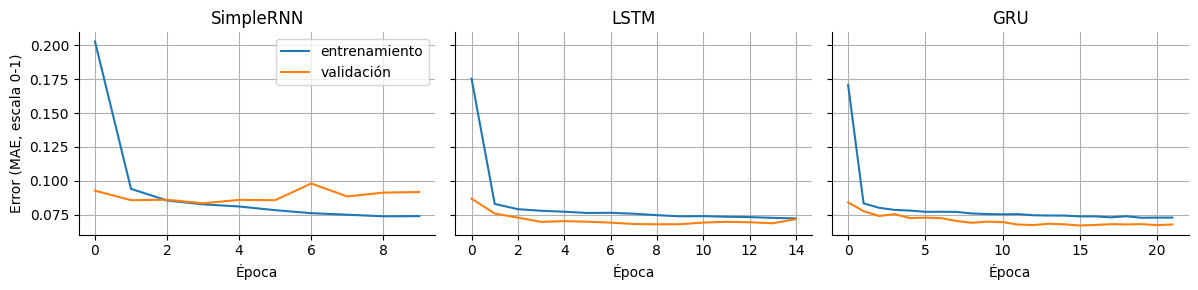

In [24]:
# Figura con 3 gráficos en fila que comparten el eje Y
fig, ejes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
# Un gráfico por red
for ax, (nombre, (m, h)) in zip(ejes, modelos.items()):
    # Curvas de pérdida de entrenamiento y de validación por época
    ax.plot(h.history["loss"], label="entrenamiento"); ax.plot(h.history["val_loss"], label="validación")
    # Título con el nombre de la red y etiqueta del eje X
    ax.set_title(nombre); ax.set_xlabel("Época")
# Etiqueta Y y leyenda solo en el primer gráfico
ejes[0].set_ylabel("Error (MAE, escala 0-1)"); ejes[0].legend()
# Ajusta márgenes y muestra la figura
plt.tight_layout(); plt.show()

### 👀 A12 · EJEMPLO — Comparar con el baseline y ver una previsión

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A12).

1. ¿Qué red es la mejor y cuánto gana al baseline?
2. ¿Con qué más hay que comparar antes de poner una red en producción?
3. ¿Por qué `inv` deshace el escalado en el gráfico?

---
**✍️ Nuestras respuestas:**

1. La **GRU**, con 3.28 frente a 4.46 del baseline: gana **1.18 puntos** (≈ 26 % menos error).
2. Con el **modelo estadístico de S12_01 (SARIMAX, 3.18)**, que es más sencillo, más explicable y además sale mejor que la red. También hay que comprobar la estabilidad con varias semillas y más periodos de prueba (backtesting), y valorar el coste de mantenimiento.
3. Porque la red predice en escala 0–1. Para dibujarla junto a la ocupación real en % hay que invertir el escalado: `valor * rango + mínimo`.

GRU                    3.28
LSTM                   3.51
SimpleRNN              4.07
Baseline estacional    4.46


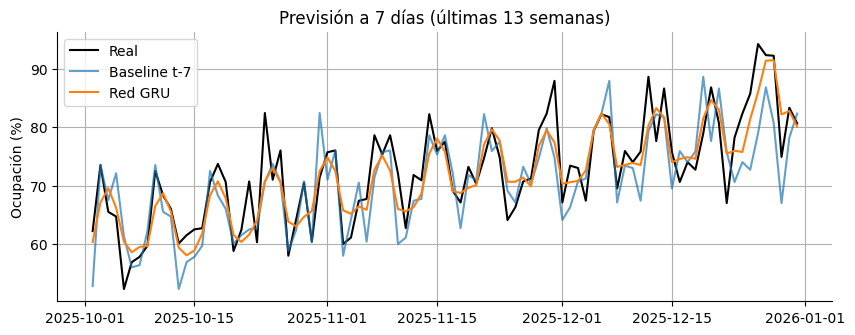

In [25]:
# Nombre de la red con menor MAE
mejor = min(resultados, key=resultados.get)
# MAE de las redes y del baseline, ordenados de menor a mayor
comp = pd.Series({**resultados, "Baseline estacional": mae_base}).sort_values()
# Muestra la tabla con 2 decimales
print(comp.round(2).to_string())

# Recupera el modelo de la mejor red
m = modelos[mejor][0]
# Sus predicciones en la prueba (escala 0-1)
pred = m.predict(X_test, verbose=0)
# Rango original de la ocupación
rango = escalador.data_max_[0] - escalador.data_min_[0]
# Deshace el escalado: valor * rango + mínimo
inv = lambda a: a * rango + escalador.data_min_[0]
# Nueva figura
fig, ax = plt.subplots()
# Real, red y baseline en % de ocupación, aplanados en una serie continua (13 x 7 días)
real_cont = inv(y_test).ravel(); pred_cont = inv(pred).ravel(); base_cont = inv(pred_base).ravel()
# Fechas de esos días de prueba
ind = df.index[orig_test[0]:orig_test[0] + len(real_cont)]
# Dibuja la serie real (negro) y el baseline t-7
ax.plot(ind, real_cont, color="black", label="Real"); ax.plot(ind, base_cont, alpha=.7, label="Baseline t-7")
# Dibuja la previsión de la mejor red
ax.plot(ind, pred_cont, label=f"Red {mejor}")
# Título, eje Y y leyenda
ax.set_title("Previsión a 7 días (últimas 13 semanas)"); ax.set_ylabel("Ocupación (%)"); ax.legend()
# Muestra el gráfico
plt.show()

### ✏️ A13 · MINI-RETO — ¿Y si la ventana es demasiado corta?

**Tu turno:** Comprueba cuánto **empeora** una red si la ventana es demasiado corta. Entrena una **GRU** con ventana de 7 días (en lugar de 28) y guarda su MAE en `mae_ventana7`. Pista: cambia `VENTANA` y vuelve a crear las ventanas con `crear_ventanas`; recuerda restaurarla al final para no romper el resto. Guarda en `ventana_larga_mejor` (True/False) si con 28 días la GRU ha ido mejor que con 7.

**Debe salir:** `GRU ventana 28: 3.28 | GRU ventana 7: 3.41` y ✔ Mini-reto correcto (tu valor para la ventana 7 puede variar algo)

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A13).

1. ¿Cuánto vale el MAE de la GRU con ventana de 7 días y con 28?
2. ¿Qué conclusión sacas sobre el largo de la ventana?
3. ¿Por qué hay que restaurar `VENTANA` al final?

---
**✍️ Nuestras respuestas:**

1. Con **28 días: 3.28**. Con 7 días, la versión anterior daba 3.69, pero **no era válida**: `entrenar("GRU")` usa siempre `X_ent` (ventanas de 28 días), así que la GRU se entrenaba con 28 días y se evaluaba con 7. Ya está corregida (entrena con `X_ent7`). Hay que volver a ejecutar el cuaderno y anotar aquí el valor nuevo (la referencia da ≈ 3.41).
2. Con un solo entrenamiento, la ventana de 28 días sale algo mejor, pero **la diferencia es pequeña** (≈ 0,1 puntos, del orden del ruido entre semillas). Con 3 semillas, la referencia obtuvo incluso lo contrario. Conclusión: el largo de la ventana **no es una decisión crítica** aquí. 28 días (4 semanas completas) es razonable, pero no está demostrado que sea el mejor.
3. Porque `VENTANA` es una **variable global** que usan `crear_ventanas` y `construir` (forma de `Input`). Si se quedara en 7, cualquier celda que se vuelva a ejecutar después (ventanas, entrenamiento, gráficos) trabajaría con la ventana equivocada o daría errores de forma.

In [26]:
# pista: guarda VENTANA, ponla a 7, rehaz ventanas de entrenamiento/prueba con crear_ventanas, entrena una GRU y restaura VENTANA = 28
# Guardamos la ventana original (28) para poder restaurarla al final
VENTANA_ORIG = VENTANA
# Acortamos la ventana a 7 días: crear_ventanas y construir leen esta variable global
VENTANA = 7
# Rehacemos las ventanas con los MISMOS orígenes: solo cambia cuántos días de historia ve la red -> X (n, 7, 6)
X_ent7, y_ent7 = crear_ventanas(orig_ent)
X_test7, y_test7 = crear_ventanas(orig_test)

# OJO: entrenar() usa siempre X_ent / y_ent (ventanas de 28 días), por eso entrenamos aquí la GRU con X_ent7
# Misma semilla que en el ejercicio 3 para que la comparación sea justa
keras.utils.set_random_seed(SEMILLA)
# GRU de 32 unidades con entrada (7, 6), porque ahora VENTANA vale 7
m7 = construir("GRU")
# Mismas condiciones: últimas 60 ventanas como validación
n_val = 60
# Mismo EarlyStopping: para si val_loss no mejora en 6 épocas y recupera los mejores pesos
parada = keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True, monitor="val_loss")
# Entrenamiento con ventanas de 7 días (máximo 40 épocas, lotes de 32)
m7.fit(X_ent7[:-n_val], y_ent7[:-n_val], validation_data=(X_ent7[-n_val:], y_ent7[-n_val:]),
       epochs=40, batch_size=32, shuffle=True, callbacks=[parada], verbose=0)
# MAE de la GRU con ventana de 7 días en las 13 semanas de prueba, en puntos de ocupación
mae_ventana7 = mae_puntos(y_test7, m7.predict(X_test7, verbose=0))
# True si la GRU con 28 días tuvo menos error que con 7 (bool() lo deja como True/False de Python)
ventana_larga_mejor = bool(resultados["GRU"] < mae_ventana7)

# Restauramos VENTANA a 28 para no romper el resto del cuaderno
VENTANA = VENTANA_ORIG

# Comprobaciones del mini-reto
assert VENTANA == 28, "Restaura VENTANA = 28 al terminar."
assert 0 < mae_ventana7 < 15, "mae_ventana7 debe ser un MAE en puntos de ocupación."
assert isinstance(ventana_larga_mejor, bool), "ventana_larga_mejor debe ser True o False."
# Muestra los dos MAE para compararlos
print(f"GRU ventana 28: {resultados['GRU']:.2f} | GRU ventana 7: {mae_ventana7:.2f}")
print("✔ Mini-reto correcto")

GRU ventana 28: 3.28 | GRU ventana 7: 3.41
✔ Mini-reto correcto


# Parte B · Explicación de cada celda y de cada resultado

Cada apartado lleva el **mismo número** que su celda de la Parte A (A1, A2…). Si una celda no te sale, mira su «Si falla».

#### A1 · Preparación — Preparar las herramientas

- **Qué hace:**
    - Carga `numpy`, `pandas`, `matplotlib`, `tensorflow`, `keras` (con sus capas) y `MinMaxScaler` de `scikit-learn`.
    - `os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"` silencia los mensajes técnicos de TensorFlow; `keras.utils.set_random_seed(SEMILLA)` fija las semillas de Python, NumPy y TensorFlow para que los resultados se repitan; `plt.rcParams.update(...)` da un estilo común a los gráficos.
- **Qué debe salir:**
    - `Listo ✔`. Importar TensorFlow tarda unos segundos.
- **Cómo leerlo:**
    - No hay que entender esta celda: solo ejecutarla **la primera**, y otra vez si reinicias el entorno.
- **Si falla:**
    - `NameError: name 'pd' is not defined` → no has ejecutado esta celda. Ejecútala y repite la que falló.
    - `ModuleNotFoundError: No module named 'tensorflow'` → fuera de Colab, instala TensorFlow en tu entorno.

## 1. Idea: una red con memoria

#### A2 · Ejemplo — Cargar la ocupación diaria

**Contexto.** Mismo problema que en `S12_01` (previsión de ocupación a 7 días), ahora con redes que «leen» la secuencia día a día y tienen memoria.

Una red normal mira cada fila por separado. Una **red recurrente** lee la secuencia paso a paso y va
actualizando un "resumen" de lo visto (su **estado**).
- **SimpleRNN**: resumen simple; tiende a olvidar lo lejano.
- **LSTM**: añade *puertas* que deciden qué recordar, qué olvidar y qué sacar.
- **GRU**: versión más ligera de la LSTM (menos puertas, más rápida).

Para entrenarlas, la serie se corta en **ventanas**: cada ejemplo es un trozo de 28 días (entrada) y los
7 días siguientes (salida).

- **Qué hace:**
    - `pd.read_csv(..., parse_dates=["fecha"]).set_index("fecha")` lee la ocupación diaria y usa la fecha como índice.
    - El `print` muestra la versión de TensorFlow y el número de filas.
- **Qué debe salir:**
    - `TensorFlow 2.21.0 | filas: 1096` (la versión puede ser otra).
- **Cómo leerlo:**
    - 1 096 días de ocupación: unos tres años de datos, pocos para una red neuronal (de ahí el cuidado con el sobreajuste).
- **Si falla:**
    - `NameError: name 'dato' is not defined` → falta ejecutar la celda de preparación.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Cuántos días de datos hay?* → **1 096** (de 2023 a 2025).
2. *¿Qué diferencia hay entre una red normal y una recurrente?* → Una red normal mira cada fila **por separado**; una recurrente lee la secuencia **paso a paso** y mantiene un **estado** (memoria).
3. *¿En qué se diferencian LSTM y GRU de SimpleRNN?* → Tienen **puertas** que deciden qué recordar y qué olvidar (la GRU, con menos puertas, es más ligera); la SimpleRNN tiende a olvidar lo lejano.

</details>

## 2. Variables de entrada y partición temporal

#### A3 · Ejemplo — Crear las variables de entrada y reservar la prueba

Cada día será un vector con: ocupación, festivo y el día de la semana y del año en forma de seno/coseno
(así "domingo" y "lunes" quedan cerca). **Todo es información conocida** hasta ese día.

- **Qué hace:**
    - `DIAS_TEST, VENTANA, HORIZONTE = 91, 28, 7` fija el tamaño de la prueba (91 días), de la ventana de entrada (28 días) y del horizonte de predicción (7 días).
    - `df` reúne, para cada día, la ocupación, el festivo y el día de la semana y del año como seno y coseno (`sem_sin`, `sem_cos`, `anio_sin`, `anio_cos`), de modo que «domingo» y «lunes» quedan cerca.
    - `n_ent` es el número de días de entrenamiento (todos menos los últimos 91).
- **Qué debe salir:**
    - `Días de entrenamiento: 1005 | días de prueba: 91`.
- **Cómo leerlo:**
    - Seis variables por día (ocupación, festivo y cuatro de calendario), todas **conocidas** hasta ese día. Los últimos 91 días (13 semanas) quedan reservados para la prueba.
- **Si falla:**
    - `NameError: name 'ocup' is not defined` → falta el ejemplo anterior.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Cuántas variables describen cada día?* → **6**: ocupación, festivo y cuatro de calendario (seno y coseno de la semana y del año).
2. *¿Por qué se usan seno y coseno para el día de la semana?* → Para que **domingo y lunes queden cerca** (el calendario es circular).
3. *¿Cuántos días hay en entrenamiento y en prueba?* → **1 005** y **91**.

</details>

## 3. Escalado SIN fuga

#### A4 · Ejercicio 1 — Escalar sin fuga de datos

Las redes aprenden mal con números grandes; se escala la ocupación a [0, 1].
**Regla de oro:** el escalador se ajusta (`fit`) **solo con el entrenamiento**; con la prueba solo se aplica (`transform`).
Si usáramos el máximo y el mínimo de toda la serie, estaríamos filtrando información del futuro.

- **Qué hace:**
    - `MinMaxScaler()` lleva los valores al rango [0, 1]. `escalador.fit(df[["ocupacion"]].iloc[:n_ent])` aprende el mínimo y el máximo **solo del entrenamiento**.
    - `escalador.transform(df[["ocupacion"]]).ravel()` aplica ese escalado a **toda** la serie y la deja en una dimensión (`ocup_esc`).
    - Las comprobaciones verifican que hay un valor por día y que en el entrenamiento el mínimo es 0 y el máximo 1.
- **Qué debe salir:**
    - `Entrenamiento escalado entre 0.00 y 1.00 · toda la serie entre 0.00 y 1.00`.
    - `✔ Ejercicio 1 correcto`.
- **Cómo leerlo:**
    - Como el escalador solo conoce el entrenamiento, los valores de la prueba pueden salir **fuera de [0, 1]** (si superan el máximo o el mínimo del pasado): es lo correcto, porque en producción tampoco se conoce el futuro.
- **Si falla:**
    - `ocup_esc debe tener una posición por día` → has transformado solo el entrenamiento: hay que transformar toda la serie.
    - `El escalador debe ajustarse solo con el entrenamiento ...` → has hecho `fit` con toda la serie.
    - `NameError: name 'n_ent' is not defined` → falta el ejemplo anterior.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Por qué el escalador se ajusta solo con el entrenamiento?* → Porque, si no, el máximo y el mínimo de toda la serie **filtrarían información del futuro** (fuga de datos).
2. *¿Qué hace `fit` y qué hace `transform`?* → `fit` **aprende** el mínimo y el máximo; `transform` **aplica** el escalado.
3. *¿Qué puede pasar con los valores escalados de la prueba?* → Que salgan **fuera de [0, 1]**, y es correcto: el escalador solo conoce el pasado.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
escalador = MinMaxScaler()
escalador.fit(df[["ocupacion"]].iloc[:n_ent])
ocup_esc = escalador.transform(df[["ocupacion"]]).ravel()
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>

#### A5 · Ejemplo — Construir la matriz de variables escaladas

- **Qué hace:**
    - `X_feat` es la tabla de variables con la ocupación sustituida por su versión escalada (`ocup_esc`).
    - `matriz` es esa tabla como array de `float32` (días × 6 variables) y `objetivo` es la ocupación escalada, lo que queremos predecir.
- **Qué debe salir:**
    - `Matriz de variables: (1096, 6)`.
- **Cómo leerlo:**
    - Cada fila es un día y cada columna una variable; de esta matriz se cortarán las ventanas.
- **Si falla:**
    - `NameError: name 'ocup_esc' is not defined` → falta el ejercicio 1.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué forma tiene la matriz de variables?* → **(1096, 6)**: 1 096 días por 6 variables.
2. *¿Qué es `objetivo`?* → La **ocupación escalada**: lo que la red debe predecir.
3. *¿Por qué se pasa a `float32`?* → Porque es el tipo de número con el que **trabaja Keras** (y ocupa menos memoria).

</details>

## 4. Ventanas deslizantes

#### A6 · Ejercicio 2 — Crear las ventanas deslizantes

Para cada posición `t` (el "origen"): entrada = días `t-28 … t-1`; salida = días `t … t+6`.

- **Qué hace:**
    - `crear_ventanas(origenes)` recorre cada origen `t` y toma como entrada los 28 días anteriores (`matriz[t - VENTANA:t]`) y como salida los 7 días siguientes (`objetivo[t:t + HORIZONTE]`); `np.array` los apila en `X` (n, 28, 6) e `y` (n, 7).
    - `orig_ent` son los orígenes de entrenamiento: todas las posiciones cuyos 7 días de futuro caen **dentro** del entrenamiento. `orig_test` es uno por semana en las 13 semanas de prueba.
    - Se crean `X_ent, y_ent` y `X_test, y_test`, se imprimen sus formas y las comprobaciones verifican las dimensiones y que el último día de la ventana del origen `t` es `t-1`.
- **Qué debe salir:**
    - `Entrenamiento: (971, 28, 6) (971, 7) | Prueba: (13, 28, 6) (13, 7)` y `✔ Ejercicio 2 correcto`.
- **Cómo leerlo:**
    - Hay 971 ejemplos de entrenamiento (muy solapados entre sí: cada ventana desplaza un solo día respecto a la anterior) y 13 de prueba, una por semana.
- **¿De dónde sale cada valor?**
    - **`VENTANA = 28`** → son **4 semanas**: un múltiplo de 7, para que la ventana contenga ciclos semanales completos. Medido sobre la validación (error medio en puntos, media de 3 semillas ± desviación): 7 días → 3,39 ± 0,11 · 14 → 3,46 ± 0,03 · **28 → 3,54 ± 0,07** · 56 → 3,39 ± 0,12. **Las diferencias están dentro del ruido** (≈ ± 0,1): ninguna ventana gana con claridad, así que 28 es una elección razonable, no la mejor demostrada.
    - **`HORIZONTE = 7`** → lo marca el negocio (prever la semana siguiente), igual que en S12_01.
- **Si falla:**
    - `X debe ser (n, 28, 6) e y (n, 7)` → los cortes de `matriz` y `objetivo` no tienen el tamaño `VENTANA` y `HORIZONTE`.
    - `El último día de la ventana del origen t es t-1` → la ventana debe terminar en `t-1` (`matriz[t - VENTANA:t]`, sin incluir `t`).
    - `NameError: name 'matriz' is not defined` → falta el ejemplo anterior.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Cuántos ejemplos de entrenamiento y de prueba salen?* → **971** y **13**.
2. *¿Qué forma tiene `X` y qué significa cada dimensión?* → `(n, 28, 6)`: **n** ejemplos, **28** días de historia y **6** variables.
3. *¿Por qué los ejemplos de entrenamiento están tan solapados?* → Porque cada ventana se desplaza **un solo día** respecto a la anterior.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
def crear_ventanas(origenes):
    X = np.array([matriz[t - VENTANA:t] for t in origenes], dtype="float32")
    y = np.array([objetivo[t:t + HORIZONTE] for t in origenes], dtype="float32")
    return X, y
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>

#### A7 · Ejemplo — Comprobar que no hay fuga de datos

**Comprobación sin fuga:** ninguna ventana de entrenamiento debe tocar el periodo de prueba.

- **Qué hace:**
    - El `assert` verifica que el último día que usa una ventana de entrenamiento (origen + 6) cae antes de `n_ent`.
    - El `print` muestra ese último día y el primer día de la prueba.
- **Qué debe salir:**
    - `Sin fuga: el último día usado en entrenamiento es 2025-10-01 y la prueba empieza el 2025-10-02`.
- **Cómo leerlo:**
    - Ninguna ventana de entrenamiento toca la prueba: el entrenamiento acaba el 1 de octubre y la prueba empieza el 2.
- **Si falla:**
    - `Fuga: una ventana de entrenamiento llega a días de prueba.` → `orig_ent` incluye orígenes cuyo futuro cae en la prueba.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué comprueba el `assert` de esta celda?* → Que **ninguna ventana de entrenamiento** llega a los días de la prueba.
2. *¿Cuál es el último día usado en entrenamiento?* → El **2025-10-01** (la prueba empieza el 2025-10-02).
3. *¿Por qué es importante esta comprobación?* → Porque una fuga haría que la evaluación sea **demasiado optimista**.

</details>

## 5. Baseline en la misma escala de evaluación

#### A8 · Ejemplo — El baseline estacional en la misma escala

El baseline estacional (repetir la última semana) sobre las mismas 13 semanas. Medimos el MAE en **puntos de ocupación**.

- **Qué hace:**
    - `mae_puntos(y_esc, pred_esc)` calcula el error absoluto medio y lo multiplica por el rango del escalador, para expresarlo en **puntos de ocupación**.
    - `pred_base` es el baseline estacional: para cada origen, repite la última semana conocida (`objetivo[o - 7:o]`). `mae_base` es su error en la prueba.
- **Qué debe salir:**
    - `MAE baseline estacional: 4.46 puntos`.
- **Cómo leerlo:**
    - Este es el listón: **4,46 puntos** de error medio. Una red solo merece la pena si lo mejora (es el mismo valor que en `S12_01`).
- **Si falla:**
    - `NameError: name 'escalador' is not defined` → falta el ejercicio 1.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Cuánto vale el MAE del baseline?* → **4,46** puntos de ocupación.
2. *¿Por qué se multiplica por el rango del escalador?* → Para **deshacer el escalado** y medir el error en puntos de ocupación, no en la escala 0–1.
3. *¿Qué hace el baseline estacional?* → **Repite la última semana** conocida como previsión de los 7 días siguientes.

</details>

## 6. Construir y entrenar las tres redes

#### A9 · Ejemplo — Definir construir y entrenar las redes

La misma estructura, cambiando solo la capa recurrente. Modelos pequeños (32 unidades) y pocas épocas para que sea rápido.
Usamos como validación las **últimas 60 ventanas del entrenamiento** (sin barajar) y *early stopping*: se para cuando deja de mejorar.

- **Qué hace:**
    - `construir(tipo)` crea un modelo con una capa de entrada (28 días × 6 variables), **una** capa recurrente de 32 unidades (`SimpleRNN`, `LSTM` o `GRU`, según `tipo`) y una capa `Dense(7)` que da los 7 días siguientes. Se compila con `adam` (tasa 0,005) y pérdida `mae`.
    - `entrenar(tipo, epocas)` fija la semilla, construye la red y la entrena con las últimas 60 ventanas del entrenamiento como validación (sin barajar esas) y `EarlyStopping` (para si la validación no mejora en 6 épocas y restaura los mejores pesos). Devuelve el modelo y su historial.
- **Qué debe salir:**
    - No imprime nada: solo define las dos funciones.
- **Cómo leerlo:**
    - Las tres redes comparten la misma estructura: cambia **solo** la capa recurrente, para que la comparación sea justa.
- **¿De dónde sale cada valor?**
    - **32 unidades** → es un tamaño habitual para series pequeñas, y **da igual**. Medido (error medio de validación en puntos, 3 semillas): 4 → 3,50 · 8 → 3,48 · 16 → 3,54 · **32 → 3,54** · 64 → 3,57 · 128 → 3,49. Todo entre 3,48 y 3,57: con 971 ejemplos muy solapados, una red de 4 unidades rinde igual que una de 128. Las grandes solo tardan más y paran antes por `EarlyStopping` (13–14 épocas frente a 35).
    - **`adam` con tasa 0,005** → es 5 veces la tasa por defecto (0,001), elegida para que converja en pocas épocas. Medido: 0,0005 → 3,56 · 0,001 → 3,50 · **0,005 → 3,54** · 0,02 → 3,43. De nuevo, dentro del ruido: la red es poco sensible a la tasa en este rango.
    - **`patience=6`** → Medido: patience 2 → 3,60 (para a las 10 épocas, algo peor) · **6 → 3,54 (19 épocas)** · 12 → 3,51 (29 épocas). Con 2 se corta demasiado pronto; de 6 en adelante apenas cambia.
    - **pérdida `mae`** → porque la métrica del negocio es el error medio en puntos de ocupación; entrenar con la misma medida con la que se evalúa evita sorpresas.
    - **últimas 60 ventanas como validación** → ≈ 2 meses, a continuación del entrenamiento (sin barajar): una validación **posterior** a los datos de entrenamiento imita el uso real.
    - **una sola capa recurrente** → con tan pocos datos una segunda capa solo añade pesos; es el punto de partida más simple.
- **Si falla:**
    - `NameError: name 'VENTANA' is not defined` → falta el ejemplo de las variables de entrada.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué cambia entre las tres redes?* → **Solo la capa recurrente** (`SimpleRNN`, `LSTM` o `GRU`).
2. *¿Qué hace `EarlyStopping(patience=6, restore_best_weights=True)`?* → Para el entrenamiento si la validación **no mejora en 6 épocas** y devuelve los pesos de la mejor época.
3. *¿Qué devuelve la capa `Dense(HORIZONTE)`?* → **7 valores**: la previsión de los 7 días siguientes.

</details>

#### A10 · Ejercicio 3 — Entrenar SimpleRNN, LSTM y GRU

**Ejercicio 3 · 🏫 en clase.** Entrena las tres redes en un diccionario `modelos` con claves `"SimpleRNN"`, `"LSTM"` y `"GRU"`,
donde cada valor es la tupla `(modelo, historial)` que devuelve `entrenar`. Después se calcula el MAE de cada una en `resultados`.

- **Qué hace:**
    - `{nombre: entrenar(nombre) for nombre in [...]}` entrena las tres redes y guarda, para cada nombre, la tupla `(modelo, historial)`.
    - La comprobación calcula, para cada una, su MAE en la prueba (`resultados`) con `mae_puntos` y escribe también cuántas épocas entrenó (`len(h.history['loss'])`).
- **Qué debe salir:**
    - `SimpleRNN  MAE prueba: 3.79 puntos | épocas: 31`, `LSTM  MAE prueba: 3.51 puntos | épocas: 15`, `GRU  MAE prueba: 3.28 puntos | épocas: 22` y `Baseline  MAE prueba: 4.46 puntos`, más `✔ Ejercicio 3 correcto`.
- **Cómo leerlo:**
    - Las tres redes **ganan al baseline** (4,46): la mejor, la GRU, con 3,28 (≈ 26 % menos de error). La LSTM paró a las 15 épocas por `EarlyStopping`. Con un solo entrenamiento y 13 semanas de prueba, las diferencias entre las tres redes son pequeñas.
- **¿De dónde sale cada valor?**
    - **¿SimpleRNN, LSTM o GRU?** → se prueban las tres porque son las tres capas recurrentes de Keras. Medido sobre la validación con 3 semillas: SimpleRNN 3,54 ± 0,07 · LSTM 3,54 ± 0,07 · **GRU 3,41 ± 0,08**. La GRU queda algo por delante, pero la diferencia es de 0,13: apenas el doble del ruido. Lo sólido es que **las tres ganan al baseline** estacional (4,46 en la prueba) con cualquiera de los valores probados.
- **Si falla:**
    - `modelos debe tener las claves SimpleRNN, LSTM y GRU` → falta alguna de las tres claves.
    - `NameError: name 'entrenar' is not defined` → falta el ejemplo anterior. Tarda un minuto en entrenar.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué MAE obtiene cada red y cuál es la mejor?* → SimpleRNN **3,79**, LSTM **3,51** y GRU **3,28**: la mejor es la **GRU**.
2. *¿Ganan las redes al baseline?* → **Sí**, las tres: el baseline tiene 4,46.
3. *¿Qué indica que la LSTM haya parado a las 15 épocas?* → Que la **validación dejó de mejorar** y `EarlyStopping` cortó el entrenamiento.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
modelos = {nombre: entrenar(nombre) for nombre in ["SimpleRNN", "LSTM", "GRU"]}

resultados = {}
for nombre, (m, h) in modelos.items():
    pred = m.predict(X_test, verbose=0)
    resultados[nombre] = mae_puntos(y_test, pred)
    print(f"{nombre:10s} MAE prueba: {resultados[nombre]:.2f} puntos | épocas: {len(h.history['loss'])}")
print(f"{'Baseline':10s} MAE prueba: {mae_base:.2f} puntos")
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>

#### A11 · Ejemplo — Ver las curvas de aprendizaje de las tres redes

- **Qué hace:**
    - Para cada red dibuja la pérdida (MAE en escala 0–1) de entrenamiento y de validación por época, en tres gráficos con el mismo eje vertical.
- **Qué debe salir:**
    - Tres gráficos (SimpleRNN, LSTM y GRU), cada uno con dos curvas.
- **Cómo leerlo:**
    - En cada una, la curva de entrenamiento baja y la de validación se estanca: es justo lo que vigila `EarlyStopping` para parar a tiempo.
- **Si falla:**
    - `NameError: name 'modelos' is not defined` → falta el ejercicio 3.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué dos curvas hay en cada gráfico?* → La **pérdida de entrenamiento** y la **de validación** por época.
2. *¿Qué señal indica que conviene parar el entrenamiento?* → Que la curva de **validación deja de bajar** mientras la de entrenamiento sigue bajando.
3. *¿Por qué comparten el eje vertical?* → Para poder **comparar las tres redes** a simple vista.

</details>

## 7. Comparar con el baseline y mirar una previsión

#### A12 · Ejemplo — Comparar con el baseline y ver una previsión

La pregunta importante no es "¿cuál red gana?" sino **"¿gana alguna al baseline?"**.

- **Qué hace:**
    - `mejor` es el nombre de la red con menor MAE y `comp` la tabla ordenada con las tres redes y el baseline.
    - El gráfico dibuja la ocupación real de las 13 semanas de prueba (en negro), la previsión del baseline y la de la mejor red; `inv` deshace el escalado para ver porcentajes de ocupación.
- **Qué debe salir:**
    - La tabla: `GRU 3.28` · `LSTM 3.51` · `SimpleRNN 3.79` · `Baseline estacional 4.46`, y un gráfico con tres líneas (real, baseline y GRU).
- **Cómo leerlo:**
    - Hay que mirar si **alguna red gana al baseline**: aquí sí, las tres. Pero en `S12_01` el modelo SARIMAX, más sencillo y explicable, logró 3,18: **la mejor red (3,28) ni siquiera lo supera**.
- **Si falla:**
    - `NameError: name 'resultados' is not defined` → falta el ejercicio 3.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué red es la mejor y cuánto gana al baseline?* → La **GRU**, con 3,28 frente a 4,46 (≈ 26 % menos de error).
2. *¿Con qué más hay que comparar antes de poner una red en producción?* → Con **modelos más sencillos**, como el SARIMAX de `S12_01` (3,18), que aquí iguala a la mejor red.
3. *¿Por qué `inv` deshace el escalado en el gráfico?* → Para dibujar la ocupación en **porcentaje real** y no en la escala 0–1.

</details>

## 8. Mini-reto integrador

#### A13 · Mini-reto — ¿Y si la ventana es demasiado corta?

- **Qué hace:**
    - `VENTANA_ORIG = VENTANA` guarda la ventana original y `VENTANA = 7` la acorta; `crear_ventanas` rehace los datos con los mismos orígenes (`X_ent7`, `X_test7`).
    - `m7` es una GRU de 32 unidades con entrada `(7, 6)`, entrenada con las mismas condiciones (validación de las últimas 60 ventanas y `EarlyStopping`). `mae_ventana7` es su MAE en la prueba.
    - `VENTANA = VENTANA_ORIG` **restaura** la ventana y `ventana_larga_mejor` es `True` si la GRU con 28 días (`resultados["GRU"]`) tuvo menos error que con 7.
- **Qué debe salir:**
    - `GRU ventana 28: 3.28 | GRU ventana 7: 3.41` y `✔ Mini-reto correcto`.
- **Cómo leerlo:**
    - Con 28 días el error es 3,28 y con 7 días 3,41: la ventana larga mejora, pero **muy poco** (0,13 puntos) y con un solo entrenamiento no es una diferencia concluyente. `ventana_larga_mejor` vale `True`.
- **¿De dónde sale cada valor?**
    - **por qué un solo entrenamiento no concluye** → se midió también con 3 semillas sobre la validación y salió al revés: **7 días → 3,39 y 28 días → 3,54**. Con ± 0,1 de ruido entre entrenamientos, la ventana no decide. Por eso el reto pide mirar el tamaño de la diferencia y no solo si `ventana_larga_mejor` es `True` o `False`.
- **Si falla:**
    - `Restaura VENTANA = 28 al terminar.` → falta `VENTANA = VENTANA_ORIG` al final.
    - `mae_ventana7 debe ser un MAE en puntos de ocupación` → has dejado el error en escala 0–1 (usa `mae_puntos`).
    - `ventana_larga_mejor debe ser True o False` → guarda una comparación (`bool(...)`), no un número.
    - `NameError: name 'resultados' is not defined` → falta el ejercicio 3.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Cuánto vale el MAE de la GRU con ventana de 7 días y con 28?* → **3,41** con 7 días y **3,28** con 28.
2. *¿Qué conclusión sacas sobre el largo de la ventana?* → Que la ventana larga mejora **un poco** (0,13 puntos), pero con un solo entrenamiento no es una diferencia concluyente.
3. *¿Por qué hay que restaurar `VENTANA` al final?* → Porque el resto del cuaderno **usa** `VENTANA = 28`; si no se restaura, las celdas siguientes darían errores o resultados distintos.

</details>

## Preguntas de reflexión
1. ¿Por qué el escalador no debe ver los datos de prueba? Explícalo con un ejemplo de este notebook.
2. ¿Ha ganado alguna red al baseline? Si no, ¿qué le dirías al cliente antes de poner una red en producción?
3. Con solo ~1000 días de datos, ¿qué riesgo hay de que la red memorice (sobreajuste)? ¿Cómo lo vigila la validación?
4. ¿Qué tres decisiones te parecen más importantes (largo de ventana, unidades, épocas)? ¿Cómo las probarías sin usar la prueba?

<details><summary>Ver respuestas (después de pensarlo)</summary>

1. Porque el mínimo y el máximo de la **prueba** son información del **futuro**: si el escalador los usara, el modelo se beneficiaría de datos que en producción no tendría y la evaluación saldría demasiado optimista. En este cuaderno, `fit` se hace solo con las primeras `n_ent` filas (hasta el 1 de octubre de 2025); con la prueba solo se aplica `transform`.
2. **Sí**, las tres redes ganan al baseline (3,28–3,79 frente a 4,46). Aun así, antes de ponerla en producción hay que decirle al cliente que el modelo SARIMAX de `S12_01` (3,18) es **más simple, rápido y explicable** y rinde igual o mejor, y que con un solo entrenamiento y 13 semanas de prueba las diferencias entre redes no son concluyentes (conviene repetir con varias semillas).
3. El riesgo es **alto**: hay unas 971 ventanas muy solapadas (casi la misma información repetida) y la red tiene miles de parámetros, así que puede memorizar. La **validación** (las últimas 60 ventanas del entrenamiento) lo vigila: cuando su pérdida deja de bajar mientras la de entrenamiento sigue bajando, hay sobreajuste y `EarlyStopping` corta el entrenamiento.
4. Las más importantes son el **largo de la ventana**, el **número de unidades** y las **épocas** (con la tasa de aprendizaje). Se prueban con la **validación** (por ejemplo, las últimas ventanas del entrenamiento o una validación cruzada por fechas), **sin tocar la prueba**, que se reserva para la medida final.

</details>

## Resumen: qué has aprendido
- Una serie se convierte en ejemplos con **ventanas**; el escalado y la validación respetan el orden del tiempo.
- **RNN / LSTM / GRU** leen la secuencia con memoria; LSTM y GRU aguantan mejor las dependencias largas.
- Con pocos datos y un patrón claro, un **baseline** o un modelo estadístico pueden igualar a una red.
- Compara siempre con la misma partición y la misma métrica (MAE en puntos de ocupación).